In [1]:
# # Do the LLM trait tags carry real signal? Downstream evaluation

In [2]:
"""Validates the LLM tags through downstream model performance (the professor's suggestion): do the 79 trait scores
predict engagement beyond what YouTube metadata already gives, and does that hold for unseen channels and within a
channel? Engagement and age are read from one pinned daily snapshot. Every model is standardized features + Lasso
with alpha chosen by an inner CV nested inside each outer fold."""
import os
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from joblib import Parallel, delayed
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.metrics import cohen_kappa_score, mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, os.path.abspath("../src"))
import config
from traits import get_traits

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="BigQuery Storage module not found")
warnings.filterwarnings("ignore", message="The least populated class")

SNAPSHOT_DATE = "2026-11-04"
SEED = 585
OUTER_FOLDS = 5
OUTER_REPEATS = 3
INNER_FOLDS = 5
N_ALPHAS = 30
N_SHUFFLES = 50
N_BOOTSTRAPS = 50
SHORTS_MAX_SECONDS = 180
ANALYSIS_DIR = "../data/analysis"
FIGURE_DIR = "../docs/figures"
AGE_CURVE_PATH = os.path.join(ANALYSIS_DIR, "age_curve.csv")
RETAG_PATH = os.path.join(ANALYSIS_DIR, "retag_scores.csv")
HUMAN_AGREEMENT_PATH = "../data/processed/agreement_overall.csv"
os.makedirs(FIGURE_DIR, exist_ok=True)

In [3]:
# ## Load tagged videos with engagement at the pinned snapshot

In [4]:
"""One row per tagged video still on the channel list. The duplicate tagging of QX3txldu5h4 keeps its earliest row."""
traits = get_traits()
trait_columns = [trait["column"] for trait in traits]
binary_columns = [trait["column"] for trait in traits if trait["scale"] == "binary"]
linear_columns = [trait["column"] for trait in traits if trait["scale"] == "linear"]
category_of = {trait["column"]: trait["category"] for trait in traits}
categories = list(dict.fromkeys(trait["category"] for trait in traits))

bq_client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)
df_videos = bq_client.query(f"""
    WITH tagged AS (
      SELECT * EXCEPT(tag_rank)
      FROM (SELECT *, ROW_NUMBER() OVER (PARTITION BY id ORDER BY tagged_at) AS tag_rank FROM youtube.llm_tagged)
      WHERE tag_rank = 1
    )
    SELECT {", ".join("t." + column for column in trait_columns)},
           t.id, v.snippet_channelId AS channel_id, c.snippet_title AS channel_title,
           v.snippet_publishedAt AS published_at, v.snippet_title AS title, v.snippet_description AS description,
           v.snippet_tags AS tags, v.duration_seconds, v.contentDetails_caption AS caption,
           v.paidProductPlacementDetails_hasPaidProductPlacement AS paid_placement,
           CAST(c.statistics_subscriberCount AS INT64) AS subscribers,
           s.age_days, s.view_count, s.like_count
    FROM tagged t
    JOIN youtube.videos v ON t.id = v.id
    JOIN youtube.channels c ON v.snippet_channelId = c.id
    JOIN youtube.video_daily_snapshots s ON s.video_id = t.id AND s.snapshot_date = '{SNAPSHOT_DATE}'
    WHERE s.is_available
    ORDER BY t.id""").to_dataframe()
df_videos = df_videos.dropna(subset=trait_columns).reset_index(drop=True)
df_videos[trait_columns] = df_videos[trait_columns].astype(int)
print(f"{len(df_videos)} videos, {df_videos['channel_id'].nunique()} channels, snapshot {SNAPSHOT_DATE}")
print(df_videos.groupby("channel_id").size().describe().round(1).to_dict())

2788 videos, 51 channels, snapshot 2026-11-04
{'count': 51.0, 'mean': 54.7, 'std': 30.2, 'min': 2.0, '25%': 35.5, '50%': 56.0, '75%': 68.5, 'max': 142.0}


In [5]:
# ## Targets, metadata features (M) and trait encodings (T)

In [6]:
published_local = df_videos["published_at"].dt.tz_convert("America/Los_Angeles")
log_age = np.log1p(df_videos["age_days"].astype(float))
df_meta = pd.DataFrame({
    "log_duration": np.log1p(df_videos["duration_seconds"]),
    "is_short": (df_videos["duration_seconds"] <= SHORTS_MAX_SECONDS).astype(int),
    "log_age": log_age,
    "log_age_sq": log_age ** 2,
    "log_subscribers": np.log1p(df_videos["subscribers"].astype(float)),
    "hour_sin": np.sin(2 * np.pi * published_local.dt.hour / 24),
    "hour_cos": np.cos(2 * np.pi * published_local.dt.hour / 24),
    "title_length": df_videos["title"].fillna("").str.len(),
    "description_length": np.log1p(df_videos["description"].fillna("").str.len()),
    "n_tags": df_videos["tags"].fillna("").apply(lambda tags: len([tag for tag in tags.split("|") if tag])),
    "has_caption": (df_videos["caption"] == "true").astype(int),
    "paid_placement": df_videos["paid_placement"].fillna(False).astype(int),
})
df_meta = pd.concat([df_meta, pd.get_dummies(published_local.dt.day_name(), prefix="weekday", drop_first=True, dtype=int)], axis=1)

df_linear = df_videos[linear_columns]
df_binary = df_videos[binary_columns]
encodings = {
    "one-hot": pd.concat([pd.get_dummies(df_linear.astype("category"), prefix_sep="=", dtype=int)
                          .drop(columns=[f"{column}=0" for column in linear_columns], errors="ignore"), df_binary], axis=1),
    "ordinal": df_videos[trait_columns],
    "coarse": pd.concat([(df_linear.isin([1, 2])).astype(int).add_suffix("=minor"),
                         (df_linear >= 3).astype(int).add_suffix("=major"), df_binary], axis=1),
    "presence": (df_videos[trait_columns] >= 1).astype(int),
}
for encoding_name, df_encoded in encodings.items():
    encodings[encoding_name] = df_encoded.loc[:, df_encoded.std() > 0]
    print(f"{encoding_name:9s} {encodings[encoding_name].shape[1]} columns")

targets = {
    "log_views": np.log1p(df_videos["view_count"].astype(float)).values,
    "log_likes": np.log1p(df_videos["like_count"].astype(float)).values,
}
channel_ids = df_videos["channel_id"].values
print(f"metadata: {df_meta.shape[1]} columns | shorts {df_meta['is_short'].mean():.0%} | median age {df_videos['age_days'].median():.0f} days")

one-hot   303 columns
ordinal   79 columns
coarse    154 columns
presence  77 columns
metadata: 18 columns | shorts 68% | median age 47 days


In [7]:
# ## Evaluation schemes and the nested-CV helper

In [8]:
"""Each scheme is 5-fold, repeated 3 times with different shuffles (15 test folds). random: KFold over videos. held-out channel: GroupKFold by channel (whole channels unseen at training; the
inner alpha search is also grouped). within-channel: folds stratified by channel so every channel is in training;
target and features are demeaned by the channel means of the training fold (channel fixed effects), so R2 measures how
well a video's deviation from its own channel's average is predicted."""
evaluations = ["random", "held-out channel", "within-channel"]
outer_folds = {"random": [], "held-out channel": [], "within-channel": []}
for repeat in range(OUTER_REPEATS):
    outer_folds["random"] += list(KFold(OUTER_FOLDS, shuffle=True, random_state=SEED + repeat).split(df_videos))
    outer_folds["held-out channel"] += list(GroupKFold(OUTER_FOLDS, shuffle=True, random_state=SEED + repeat).split(df_videos, groups=channel_ids))
    outer_folds["within-channel"] += list(StratifiedKFold(OUTER_FOLDS, shuffle=True, random_state=SEED + repeat).split(df_videos, channel_ids))


def demean_by_channel(values_train, values_test, channels_train, channels_test):
    """Subtract each channel's training-fold mean from training and test rows."""
    df_train = pd.DataFrame(values_train)
    channel_means = df_train.groupby(channels_train).mean()
    return (values_train - channel_means.loc[channels_train].values,
            values_test - channel_means.loc[channels_test].values)


def fit_fold(x, y, evaluation, fold_index, model):
    """Fit one outer fold (alpha chosen by inner CV on the training part only) and score its test part."""
    train_index, test_index = outer_folds[evaluation][fold_index]
    x_train, x_test, y_train, y_test = x[train_index], x[test_index], y[train_index], y[test_index]
    if evaluation == "within-channel":
        x_train, x_test = demean_by_channel(x_train, x_test, channel_ids[train_index], channel_ids[test_index])
        y_train, y_test = demean_by_channel(y_train.reshape(-1, 1), y_test.reshape(-1, 1), channel_ids[train_index], channel_ids[test_index])
        y_train, y_test = y_train.ravel(), y_test.ravel()
    if evaluation == "held-out channel":
        inner = list(GroupKFold(INNER_FOLDS).split(x_train, groups=channel_ids[train_index]))
    else:
        inner = list(KFold(INNER_FOLDS, shuffle=True, random_state=SEED).split(x_train))
    if model == "ridge":
        regressor = RidgeCV(alphas=np.logspace(-1, 5, N_ALPHAS), cv=inner)
    else:
        regressor = LassoCV(alphas=N_ALPHAS, cv=inner, max_iter=5000, random_state=SEED)
    pipeline = make_pipeline(StandardScaler(), regressor).fit(x_train, y_train)
    predicted = pipeline.predict(x_test)
    return {"fold": fold_index, "r2": r2_score(y_test, predicted), "mae": mean_absolute_error(y_test, predicted),
            "n_nonzero": int((np.abs(pipeline[-1].coef_) > 1e-10).sum())}


def run_cv(df_x, y, evaluation, model="lasso", **labels):
    """Outer CV for one feature matrix; returns one row per fold, tagged with the given labels."""
    x = df_x.to_numpy(dtype=float)
    fold_rows = Parallel(n_jobs=-1)(
        delayed(fit_fold)(x, y, evaluation, fold_index, model) for fold_index in range(len(outer_folds[evaluation])))
    return [{**labels, "evaluation": evaluation, "model": model, **fold_row} for fold_row in fold_rows]


def summarize(df_folds, by):
    """Mean and sd over folds of R2 and MAE, plus the paired gain in R2 over the matching metadata-only folds."""
    df_summary = df_folds.groupby(by, sort=False).agg(
        r2_mean=("r2", "mean"), r2_sd=("r2", "std"), mae_mean=("mae", "mean"), mae_sd=("mae", "std"),
        gain_mean=("r2_gain", "mean"), gain_sd=("r2_gain", "std"), n_nonzero=("n_nonzero", "median"), n_folds=("fold", "count"))
    return df_summary.round(4).reset_index()

In [9]:
# ## Experiment 1: metadata alone vs metadata + traits, each encoding

In [10]:
fold_rows = []
for target_name, y in targets.items():
    for evaluation in evaluations:
        fold_rows += run_cv(df_meta, y, evaluation, experiment="1 main", target=target_name, features="M", encoding="none")
        fold_rows += run_cv(df_meta, y, evaluation, "ridge", experiment="1 main", target=target_name, features="M", encoding="none")
        for encoding_name, df_encoded in encodings.items():
            df_x = pd.concat([df_meta, df_encoded], axis=1)
            fold_rows += run_cv(df_x, y, evaluation, experiment="1 main", target=target_name, features="M+T", encoding=encoding_name)
            fold_rows += run_cv(df_encoded, y, evaluation, experiment="1 main", target=target_name, features="T only", encoding=encoding_name)
        for encoding_name in ["one-hot", "ordinal"]:
            df_x = pd.concat([df_meta, encodings[encoding_name]], axis=1)
            fold_rows += run_cv(df_x, y, evaluation, "ridge", experiment="1 main", target=target_name, features="M+T", encoding=encoding_name)
df_main_folds = pd.DataFrame(fold_rows)

df_base = df_main_folds[df_main_folds["features"] == "M"][["target", "evaluation", "model", "fold", "r2"]].rename(columns={"r2": "r2_base"})
df_main_folds = df_main_folds.merge(df_base, on=["target", "evaluation", "model", "fold"])
df_main_folds["r2_gain"] = df_main_folds["r2"] - df_main_folds["r2_base"]
df_main = summarize(df_main_folds, ["experiment", "target", "model", "features", "encoding", "evaluation"])
df_main[df_main["model"] == "lasso"].pivot_table(index=["target", "features", "encoding"], columns="evaluation",
                                                 values=["r2_mean", "gain_mean", "gain_sd"], sort=False).round(3)

r2_mean                                 gain_mean  \
evaluation                   random held-out channel within-channel    random   
target    features encoding                                                     
log_views M        none       0.339            0.006          0.190     0.000   
          M+T      one-hot    0.610            0.135          0.200     0.271   
                   ordinal    0.599            0.171          0.204     0.260   
                   coarse     0.601            0.147          0.200     0.262   
                   presence   0.530            0.075          0.185     0.191   
          T only   one-hot    0.482            0.057          0.077     0.143   
                   ordinal    0.468            0.087          0.088     0.129   
                   coarse     0.468            0.075          0.077     0.129   
                   presence   0.381           -0.011          0.073     0.042   
log_likes M        none       0.325            0.044          0.124     0.000   
          M+T      one-hot    0.602            0.122          0.146     0.277   
                   ordinal    0.592            0.160          0.157     0.267   
                   coarse     0.595            0.154          0.148     0.270   
                   presence   0.514            0.094          0.132     0.189   
          T only   one-hot    0.488            0.024          0.068     0.163   
                   ordinal    0.479            0.070          0.068     0.154   
                   coarse     0.480            0.043          0.062     0.154   
                   presence   0.379           -0.021          0.046     0.054   

                                                            gain_sd  \
evaluation                  held-out channel within-channel  random   
target    features encoding                                           
log_views M        none                0.000          0.000   0.000   
          M+T      one-hot             0.128          0.009   0.020   
                   ordinal             0.164          0.014   0.023   
                   coarse              0.141          0.010   0.022   
                   presence            0.068         -0.006   0.018   
          T only   one-hot             0.051         -0.114   0.027   
                   ordinal             0.081         -0.103   0.036   
                   coarse              0.069         -0.113   0.033   
                   presence           -0.017         -0.117   0.035   
log_likes M        none                0.000          0.000   0.000   
          M+T      one-hot             0.077          0.022   0.022   
                   ordinal             0.116          0.033   0.026   
                   coarse              0.110          0.024   0.026   
                   presence            0.049          0.008   0.020   
          T only   one-hot            -0.020         -0.056   0.030   
                   ordinal             0.026         -0.056   0.038   
                   coarse             -0.002         -0.062   0.036   
                   presence           -0.066         -0.079   0.037   

                                                             
evaluation                  held-out channel within-channel  
target    features encoding                                  
log_views M        none                0.000          0.000  
          M+T      one-hot             0.148          0.012  
                   ordinal             0.175          0.012  
                   coarse              0.159          0.012  
                   presence            0.160          0.010  
          T only   one-hot             0.288          0.020  
                   ordinal             0.258          0.020  
                   coarse              0.271          0.018  
                   presence            0.280          0.018  
log_likes M        none                0.000          0.000  
          M+T      one-hot  

In [11]:
df_main[df_main["model"] == "ridge"][["target", "features", "encoding", "evaluation", "r2_mean", "r2_sd", "gain_mean", "gain_sd"]]

,target,features,encoding,evaluation,r2_mean,r2_sd,gain_mean,gain_sd
1,log_views,M,none,random,0.3379,0.0302,0.0000,0.0000
10,log_views,M+T,one-hot,random,0.5981,0.0192,0.2601,0.0212
11,log_views,M+T,ordinal,random,0.5983,0.0228,0.2604,0.0250
13,log_views,M,none,held-out channel,-0.0069,0.2818,0.0000,0.0000
22,log_views,M+T,one-hot,held-out channel,0.1514,0.2315,0.1583,0.1945
23,log_views,M+T,ordinal,held-out channel,0.1599,0.2482,0.1668,0.1709
25,log_views,M,none,within-channel,0.1899,0.0216,0.0000,0.0000
34,log_views,M+T,one-hot,within-channel,0.1749,0.0265,-0.0149,0.0182
35,log_views,M+T,ordinal,within-channel,0.1958,0.0272,0.0060,0.0155
37,log_likes,M,none,random,0.3238,0.0285,0.0000,0.0000


In [12]:
# ## Experiment 2: which trait categories carry the signal

In [13]:
"""Ordinal encoding (one column per trait). Drop-one: M + every category except one. Only-one: M + a single category.
Gains are paired against the same folds' metadata-only Lasso."""
ABLATION_ENCODING = "ordinal"
y = targets["log_views"]
fold_rows = []
for evaluation in evaluations:
    for category in categories:
        kept = [column for column in encodings[ABLATION_ENCODING].columns if category_of[column] != category]
        only = [column for column in encodings[ABLATION_ENCODING].columns if category_of[column] == category]
        fold_rows += run_cv(pd.concat([df_meta, encodings[ABLATION_ENCODING][kept]], axis=1), y, evaluation,
                            experiment="2 drop one category", target="log_views", features=f"M+T minus {category}", encoding=ABLATION_ENCODING)
        fold_rows += run_cv(pd.concat([df_meta, encodings[ABLATION_ENCODING][only]], axis=1), y, evaluation,
                            experiment="2 only one category", target="log_views", features=f"M+{category}", encoding=ABLATION_ENCODING)
df_ablation_folds = pd.DataFrame(fold_rows).merge(df_base, on=["target", "evaluation", "model", "fold"])
df_ablation_folds["r2_gain"] = df_ablation_folds["r2"] - df_ablation_folds["r2_base"]
df_ablation = summarize(df_ablation_folds, ["experiment", "target", "model", "features", "encoding", "evaluation"])
df_ablation.pivot_table(index=["experiment", "features"], columns="evaluation", values=["gain_mean", "gain_sd"], sort=False).round(3)

gain_mean                   \
evaluation                                        random held-out channel   
experiment          features                                                
2 drop one category M+T minus Format               0.240            0.172   
                    M+T minus Tone and Emotion     0.255            0.172   
                    M+T minus Production           0.238            0.109   
                    M+T minus Audience Hooks       0.236            0.135   
                    M+T minus Subject Matter       0.234            0.188   
2 only one category M+Format                       0.126           -0.019   
                    M+Tone and Emotion             0.084            0.097   
                    M+Production                   0.146            0.184   
                    M+Audience Hooks               0.116            0.101   
                    M+Subject Matter               0.128           -0.030   

                                                              gain_sd  \
evaluation                                     within-channel  random   
experiment          features                                            
2 drop one category M+T minus Format                    0.010   0.022   
                    M+T minus Tone and Emotion          0.010   0.022   
                    M+T minus Production                0.014   0.023   
                    M+T minus Audience Hooks            0.011   0.021   
                    M+T minus Subject Matter            0.015   0.020   
2 only one category M+Format                            0.004   0.013   
                    M+Tone and Emotion                  0.014   0.018   
                    M+Production                        0.001   0.013   
                    M+Audience Hooks                    0.011   0.021   
                    M+Subject Matter                   -0.008   0.025   

                                                                                
evaluation                                     held-out channel within-channel  
experiment          features                                                    
2 drop one category M+T minus Format                      0.176          0.013  
                    M+T minus Tone and Emotion            0.191          0.013  
                    M+T minus Production                  0.175          0.012  
                    M+T minus Audience Hooks              0.162          0.009  
                    M+T minus Subject Matter              0.166          0.013  
2 only one category M+Format                              0.121          0.009  
                    M+Tone and Emotion                    0.110          0.009  
                    M+Production                          0.144          0.007  
                    M+Audience Hooks                      0.152          0.011  
                    M+Subject Matter                      0.094          0.008

In [14]:
# ## Experiment 3: shuffle controls

In [15]:
"""(a) global: trait rows permuted across all videos (destroys every link between traits and video).
(b) within channel: trait rows permuted only among videos of the same channel (keeps each channel's trait mix,
destroys which video got which tags). If (b) scores like the real traits, the traits mostly act as channel identity."""
df_ordinal = encodings[ABLATION_ENCODING]
rng = np.random.default_rng(SEED)
fold_rows = []
for shuffle_index in range(N_SHUFFLES):
    global_order = rng.permutation(len(df_videos))
    within_order = np.arange(len(df_videos))
    for channel_id, df_channel in df_videos.groupby("channel_id"):
        within_order[df_channel.index] = rng.permutation(df_channel.index)
    df_global = df_ordinal.iloc[global_order].reset_index(drop=True)
    df_within = df_ordinal.iloc[within_order].reset_index(drop=True)
    for evaluation in evaluations:
        fold_rows += run_cv(pd.concat([df_meta, df_global], axis=1), y, evaluation, experiment="3 shuffle global",
                            target="log_views", features="M+T shuffled globally", encoding=ABLATION_ENCODING, shuffle=shuffle_index)
        fold_rows += run_cv(pd.concat([df_meta, df_within], axis=1), y, evaluation, experiment="3 shuffle within channel",
                            target="log_views", features="M+T shuffled within channel", encoding=ABLATION_ENCODING, shuffle=shuffle_index)
df_shuffle_folds = pd.DataFrame(fold_rows).merge(df_base, on=["target", "evaluation", "model", "fold"])
df_shuffle_folds["r2_gain"] = df_shuffle_folds["r2"] - df_shuffle_folds["r2_base"]
df_shuffle_runs = df_shuffle_folds.groupby(["experiment", "evaluation", "shuffle"], sort=False)[["r2", "mae", "r2_gain"]].mean().reset_index()
df_shuffle = df_shuffle_runs.groupby(["experiment", "evaluation"], sort=False).agg(
    r2_mean=("r2", "mean"), r2_sd=("r2", "std"), mae_mean=("mae", "mean"), mae_sd=("mae", "std"),
    gain_mean=("r2_gain", "mean"), gain_sd=("r2_gain", "std"), gain_p95=("r2_gain", lambda gain: gain.quantile(0.95)),
    n_runs=("shuffle", "count")).reset_index()

df_real = df_main[(df_main["target"] == "log_views") & (df_main["model"] == "lasso") & (df_main["encoding"] == ABLATION_ENCODING)
                  & (df_main["features"] == "M+T")][["evaluation", "gain_mean"]].rename(columns={"gain_mean": "real_gain"})
df_shuffle = df_shuffle.merge(df_real, on="evaluation")
df_shuffle["share_of_shuffles_at_or_above_real"] = [
    (df_shuffle_runs[(df_shuffle_runs["experiment"] == row["experiment"]) & (df_shuffle_runs["evaluation"] == row["evaluation"])]["r2_gain"]
     >= row["real_gain"]).mean() for _, row in df_shuffle.iterrows()]
df_shuffle.round(4)

,experiment,evaluation,r2_mean,r2_sd,mae_mean,mae_sd,gain_mean,gain_sd,gain_p95,n_runs,real_gain,share_of_shuffles_at_or_above_real
0,3 shuffle global,random,0.3356,0.0013,1.4763,0.0016,-0.0035,0.0013,-0.0014,50,0.2597,0.0
1,3 shuffle within channel,random,0.5864,0.0055,1.1452,0.0089,0.2473,0.0055,0.2571,50,0.2597,0.0
2,3 shuffle global,held-out channel,0.0062,0.0005,1.7554,0.0001,-0.0001,0.0005,0.0000,50,0.1643,0.0
3,3 shuffle within channel,held-out channel,0.1407,0.0127,1.5938,0.0129,0.1343,0.0127,0.1505,50,0.1643,0.0
4,3 shuffle global,within-channel,0.1837,0.0015,0.7751,0.0008,-0.0069,0.0015,-0.0044,50,0.0136,0.0
5,3 shuffle within channel,within-channel,0.1825,0.0013,0.7754,0.0006,-0.0080,0.0013,-0.0059,50,0.0136,0.0


In [16]:
# ## Experiment 4: which traits survive

In [17]:
"""Lasso (alpha by 5-fold CV) refit on bootstrap resamples of channels' videos, M + ordinal traits. Pooled: raw log
views. Within channel: log views and features demeaned by channel (full-data channel means). Frequency = share of
resamples with a nonzero coefficient; sign = median coefficient among resamples where selected. These are
associations, not causal effects."""
df_x_full = pd.concat([df_meta, df_ordinal], axis=1)
x_pooled = df_x_full.to_numpy(dtype=float)
x_within = (df_x_full - df_x_full.groupby(channel_ids).transform("mean")).to_numpy(dtype=float)
y_within = y - pd.Series(y).groupby(channel_ids).transform("mean").to_numpy()


def bootstrap_coefficients(x, y_values, bootstrap_index):
    """Standardized Lasso coefficients on one bootstrap resample of videos."""
    rows = np.random.default_rng(SEED + bootstrap_index).integers(0, len(y_values), len(y_values))
    pipeline = make_pipeline(StandardScaler(), LassoCV(alphas=N_ALPHAS, cv=INNER_FOLDS, max_iter=5000, random_state=SEED))
    return pipeline.fit(x[rows], y_values[rows])[-1].coef_


selection_tables = []
for scope_name, x_scope, y_scope in [["pooled", x_pooled, y], ["within channel", x_within, y_within]]:
    coefficients = np.array(Parallel(n_jobs=-1)(delayed(bootstrap_coefficients)(x_scope, y_scope, bootstrap_index)
                                                for bootstrap_index in range(N_BOOTSTRAPS)))
    selected = np.abs(coefficients) > 1e-10
    median_selected = [np.median(coefficients[selected[:, column_index], column_index]) if selected[:, column_index].any() else 0.0
                       for column_index in range(coefficients.shape[1])]
    selection_tables.append(pd.DataFrame({"scope": scope_name, "feature": df_x_full.columns, "selection_freq": selected.mean(axis=0),
                                          "median_std_coef": median_selected}))
df_selection = pd.concat(selection_tables, ignore_index=True)
df_selection["category"] = df_selection["feature"].map(category_of).fillna("Metadata")
df_selection["share_of_videos_nonzero"] = df_selection["feature"].apply(
    lambda feature: (df_videos[feature] > 0).mean() if feature in trait_columns else np.nan)
df_selection["n_channels_nonzero"] = df_selection["feature"].apply(
    lambda feature: df_videos[df_videos[feature] > 0]["channel_id"].nunique() if feature in trait_columns else np.nan)
df_selection["top_channel_share"] = df_selection["feature"].apply(
    lambda feature: df_videos[df_videos[feature] > 0]["channel_id"].value_counts(normalize=True).iloc[0]
    if feature in trait_columns and (df_videos[feature] > 0).any() else np.nan)
df_selection.to_csv(os.path.join(ANALYSIS_DIR, "trait_selection_frequency.csv"), index=False)
df_top_traits = (df_selection[df_selection["category"] != "Metadata"].sort_values(["scope", "selection_freq"], ascending=[True, False])
                 .groupby("scope").head(15))
df_top_traits.round(3)

,scope,feature,selection_freq,median_std_coef,category,share_of_videos_nonzero,n_channels_nonzero,top_channel_share
18,pooled,tutorial,1.00,0.118,Format,0.133,35.0,0.156
22,pooled,challenge,1.00,-0.187,Format,0.247,45.0,0.145
26,pooled,comparison,1.00,0.107,Format,0.309,48.0,0.066
28,pooled,transformation,1.00,0.072,Format,0.085,34.0,0.148
35,pooled,documentary_investigation,1.00,0.136,Format,0.269,39.0,0.085
36,pooled,gameplay,1.00,-0.132,Format,0.037,25.0,0.304
37,pooled,compilation,1.00,-0.102,Format,0.061,31.0,0.172
39,pooled,travel_exploration,1.00,-0.129,Format,0.114,33.0,0.169
41,pooled,experiment,1.00,0.155,Format,0.120,35.0,0.116
47,pooled,explainer_video_essay,1.00,-0.206,Format,0.366,43.0,0.079


In [18]:
# ## Age-normalized target (if the age curve exists)

In [19]:
"""Projects each video's log views to a reference age using the shared age curve (columns: format short/long,
age_days, cumulative_log_growth): log views at reference = log views - growth(age) + growth(reference). The
metadata set keeps log age, so this mainly tests whether the trait gain survives a cleaner target."""
age_rows = []
if os.path.exists(AGE_CURVE_PATH):
    df_age_curve = pd.read_csv(AGE_CURVE_PATH)
    print(df_age_curve.head(), df_age_curve.shape)
    reference_age = 30
    video_format = np.where(df_videos["duration_seconds"] <= SHORTS_MAX_SECONDS, "short", "long")
    growth_at_age = np.zeros(len(df_videos))
    growth_at_reference = np.zeros(len(df_videos))
    for format_name, df_format_curve in df_age_curve.groupby("format"):
        df_format_curve = df_format_curve.sort_values("age_days")
        is_format = video_format == format_name
        growth_at_age[is_format] = np.interp(df_videos.loc[is_format, "age_days"].astype(float), df_format_curve["age_days"],
                                             df_format_curve["cumulative_log_growth"])
        growth_at_reference[is_format] = np.interp(reference_age, df_format_curve["age_days"], df_format_curve["cumulative_log_growth"])
    y_age_normalized = targets["log_views"] - growth_at_age + growth_at_reference
    for evaluation in evaluations:
        age_rows += run_cv(df_meta, y_age_normalized, evaluation, experiment="5 age-normalized", target=f"log_views_at_{reference_age}d",
                           features="M", encoding="none")
        age_rows += run_cv(pd.concat([df_meta, df_ordinal], axis=1), y_age_normalized, evaluation, experiment="5 age-normalized",
                           target=f"log_views_at_{reference_age}d", features="M+T", encoding=ABLATION_ENCODING)
else:
    print(f"{AGE_CURVE_PATH} not found; age-normalized run skipped")
df_age = pd.DataFrame()
if age_rows:
    df_age_folds = pd.DataFrame(age_rows)
    df_age_base = df_age_folds[df_age_folds["features"] == "M"][["evaluation", "fold", "r2"]].rename(columns={"r2": "r2_base"})
    df_age_folds = df_age_folds.merge(df_age_base, on=["evaluation", "fold"])
    df_age_folds["r2_gain"] = df_age_folds["r2"] - df_age_folds["r2_base"]
    df_age = summarize(df_age_folds, ["experiment", "target", "model", "features", "encoding", "evaluation"])
df_age

  format  age_days  cumulative_log_growth    ci_low   ci_high  \
0   long       1.0               0.000000  0.000000  0.000000   
1   long       2.0               0.263307  0.236539  0.304290   
2   long       3.0               0.390674  0.353875  0.442925   
3   long       4.0               0.477443  0.432778  0.540678   
4   long       5.5               0.568541  0.512004  0.645937   

   adjust_to_ref_7d  adjust_to_ref_7d_ci_low  adjust_to_ref_7d_ci_high  \
0          0.623514                 0.559059                  0.710873   
1          0.360207                 0.315186                  0.426708   
2          0.232840                 0.197213                  0.283531   
3          0.146072                 0.118966                  0.184736   
4          0.054973                 0.042627                  0.071857   

   adjust_to_ref_30d  adjust_to_ref_30d_ci_low  adjust_to_ref_30d_ci_high  \
0           0.796445                  0.703025                   0.921439   
1         

,experiment,target,model,features,encoding,evaluation,r2_mean,r2_sd,mae_mean,mae_sd,gain_mean,gain_sd,n_nonzero,n_folds
0,5 age-normalized,log_views_at_30d,lasso,M,none,random,0.3128,0.0287,1.4643,0.0521,0.0000,0.0000,12.0,15
1,5 age-normalized,log_views_at_30d,lasso,M+T,ordinal,random,0.5833,0.0233,1.1091,0.0540,0.2705,0.0231,83.0,15
2,5 age-normalized,log_views_at_30d,lasso,M,none,held-out channel,-0.0084,0.2827,1.7358,0.2489,0.0000,0.0000,4.0,15
3,5 age-normalized,log_views_at_30d,lasso,M+T,ordinal,held-out channel,0.1441,0.2615,1.5548,0.2622,0.1525,0.1323,31.0,15
4,5 age-normalized,log_views_at_30d,lasso,M,none,within-channel,0.1688,0.0207,0.7706,0.0255,0.0000,0.0000,12.0,15
5,5 age-normalized,log_views_at_30d,lasso,M+T,ordinal,within-channel,0.1877,0.0221,0.7589,0.0270,0.0189,0.0097,42.0,15


In [20]:
# ## Save the results table

In [21]:
df_shuffle_out = df_shuffle.assign(
    target="log_views", model="lasso", features=lambda df: df["experiment"].str.replace("3 shuffle ", "M+T shuffled "),
    encoding=ABLATION_ENCODING, n_folds=OUTER_FOLDS * OUTER_REPEATS)
df_results = pd.concat([df_main, df_ablation, df_shuffle_out, df_age], ignore_index=True)
df_results = df_results[["experiment", "target", "model", "features", "encoding", "evaluation", "r2_mean", "r2_sd",
                         "mae_mean", "mae_sd", "gain_mean", "gain_sd", "gain_p95", "share_of_shuffles_at_or_above_real",
                         "n_nonzero", "n_folds", "n_runs"]]
df_results.insert(0, "n_videos", len(df_videos))
df_results.insert(1, "n_channels", df_videos["channel_id"].nunique())
df_results.to_csv(os.path.join(ANALYSIS_DIR, "downstream_results.csv"), index=False)
print(f"{len(df_results)} rows -> {ANALYSIS_DIR}/downstream_results.csv")

114 rows -> ../data/analysis/downstream_results.csv


In [22]:
# ## Figure: trait gain by evaluation, with shuffle controls

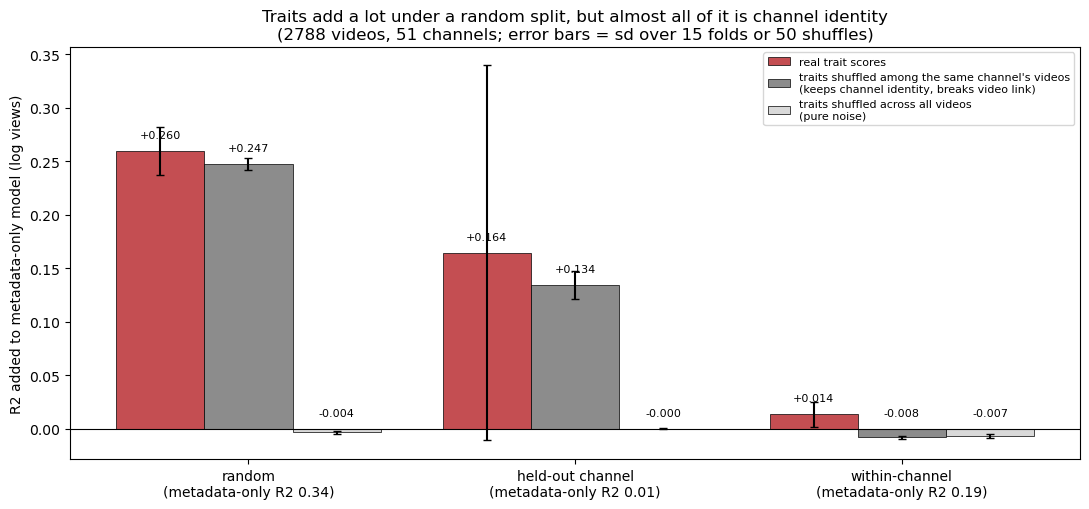

In [23]:
"""Ordinal encoding, log views. Real = paired gain over metadata-only (sd over folds). Shuffled = mean gain over the
shuffle runs (sd over runs)."""
df_real_gain = df_main[(df_main["target"] == "log_views") & (df_main["model"] == "lasso") & (df_main["features"] == "M+T")
                       & (df_main["encoding"] == ABLATION_ENCODING)].set_index("evaluation").loc[evaluations]
df_within_gain = df_shuffle[df_shuffle["experiment"] == "3 shuffle within channel"].set_index("evaluation").loc[evaluations]
df_global_gain = df_shuffle[df_shuffle["experiment"] == "3 shuffle global"].set_index("evaluation").loc[evaluations]
df_base_r2 = df_main[(df_main["target"] == "log_views") & (df_main["model"] == "lasso") & (df_main["features"] == "M")].set_index("evaluation")
bar_groups = [["real trait scores", df_real_gain, "#C44E52"],
              ["traits shuffled among the same channel's videos\n(keeps channel identity, breaks video link)", df_within_gain, "#8C8C8C"],
              ["traits shuffled across all videos\n(pure noise)", df_global_gain, "#D9D9D9"]]
positions = np.arange(len(evaluations))
fig, axis = plt.subplots(figsize=(11, 5.2))
for group_index, [label, df_gain, color] in enumerate(bar_groups):
    offsets = positions + (group_index - 1) * 0.27
    axis.bar(offsets, df_gain["gain_mean"], 0.27, yerr=df_gain["gain_sd"], color=color, capsize=3, label=label, edgecolor="black", linewidth=0.5)
    for offset, gain in zip(offsets, df_gain["gain_mean"]):
        axis.text(offset, max(gain, 0) + 0.012, f"{gain:+.3f}", ha="center", fontsize=8)
axis.axhline(0, color="black", linewidth=0.8)
axis.set_xticks(positions, [f"{evaluation}\n(metadata-only R2 {df_base_r2.loc[evaluation, 'r2_mean']:.2f})" for evaluation in evaluations])
axis.set_ylabel("R2 added to metadata-only model (log views)")
axis.legend(fontsize=8, loc="upper right")
axis.set_title(f"Traits add a lot under a random split, but almost all of it is channel identity\n"
               f"({len(df_videos)} videos, {df_videos['channel_id'].nunique()} channels; error bars = sd over "
               f"{OUTER_FOLDS * OUTER_REPEATS} folds or {N_SHUFFLES} shuffles)")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "downstream_gain_by_eval.png"), dpi=150)
plt.show()

In [24]:
# ## Figure: which categories carry the signal

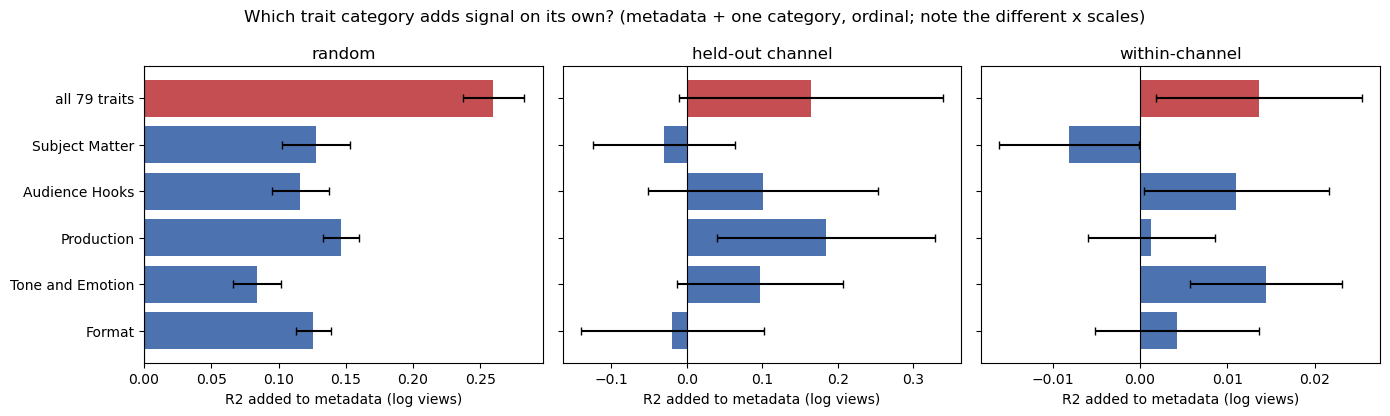

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for axis, evaluation in zip(axes, evaluations):
    df_only = df_ablation[(df_ablation["experiment"] == "2 only one category") & (df_ablation["evaluation"] == evaluation)]
    df_all = df_main[(df_main["target"] == "log_views") & (df_main["model"] == "lasso") & (df_main["features"] == "M+T")
                     & (df_main["encoding"] == ABLATION_ENCODING) & (df_main["evaluation"] == evaluation)]
    labels = [features.replace("M+", "") for features in df_only["features"]] + ["all 79 traits"]
    axis.barh(labels, list(df_only["gain_mean"]) + list(df_all["gain_mean"]), xerr=list(df_only["gain_sd"]) + list(df_all["gain_sd"]),
              color=["#4C72B0"] * len(df_only) + ["#C44E52"], capsize=3)
    axis.axvline(0, color="black", linewidth=0.8)
    axis.set_title(evaluation)
    axis.set_xlabel("R2 added to metadata (log views)")
fig.suptitle("Which trait category adds signal on its own? (metadata + one category, ordinal; note the different x scales)")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "downstream_gain_by_category.png"), dpi=150)
plt.show()

In [26]:
# ## Experiment 5: test-retest consistency of the tagger

In [27]:
"""The same videos re-tagged with the identical prompt, model and schema (scratch script, results in
data/analysis/retag_scores.csv only). Compared against their original llm_tagged scores. The all-zeros baseline is
the exact agreement one would get by predicting 0 everywhere (i.e. how much exact agreement the sparsity alone gives)."""
df_retag = pd.read_csv(RETAG_PATH).drop_duplicates("id")
df_original = df_videos[df_videos["id"].isin(df_retag["id"])][["id"] + trait_columns]
df_first = df_original.melt(id_vars="id", var_name="trait", value_name="first")
df_second = df_retag[["id"] + trait_columns].melt(id_vars="id", var_name="trait", value_name="second")
df_pairs = df_first.merge(df_second, on=["id", "trait"]).dropna()
df_pairs["category"] = df_pairs["trait"].map(category_of)
df_pairs["scale"] = np.where(df_pairs["trait"].isin(binary_columns), "binary", "linear")
df_pairs["abs_diff"] = (df_pairs["first"] - df_pairs["second"]).abs()


def agreement(df_part):
    """Exact / within-1 / mean absolute difference / present-absent agreement, plus chance-style baselines."""
    first_present = df_part["first"] >= 1
    second_present = df_part["second"] >= 1
    return pd.Series({
        "n_scores": len(df_part), "exact": (df_part["abs_diff"] == 0).mean(), "within_1": (df_part["abs_diff"] <= 1).mean(),
        "MAE": df_part["abs_diff"].mean(), "presence_agree": (first_present == second_present).mean(),
        "presence_F1": 2 * (first_present & second_present).sum() / max(first_present.sum() + second_present.sum(), 1),
        "all_zeros_exact": (df_part["first"] == 0).mean(),
        "weighted_kappa": cohen_kappa_score(df_part["first"], df_part["second"], weights="quadratic"),
        "mean_shift_second_minus_first": (df_part["second"] - df_part["first"]).mean()})


df_retag_overall = agreement(df_pairs).to_frame("test-retest (AI vs AI)").T
df_human = pd.read_csv(HUMAN_AGREEMENT_PATH, index_col=0).loc[["all traits"]].rename(index={"all traits": "AI vs human (5 videos)"})
df_compare = pd.concat([df_retag_overall, df_human[["n_scores", "exact", "within_1", "MAE", "presence_agree", "F1", "all_zeros_exact"]]
                        .rename(columns={"F1": "presence_F1"})])
df_retag_category = df_pairs.groupby("category").apply(agreement, include_groups=False)
df_retag_trait = df_pairs.groupby("trait").apply(agreement, include_groups=False)
df_retag_trait["category"] = df_retag_trait.index.map(category_of)
df_retag_trait["share_nonzero_original"] = [(df_videos[trait] > 0).mean() for trait in df_retag_trait.index]
df_retag_trait.to_csv(os.path.join(ANALYSIS_DIR, "retag_consistency_by_trait.csv"))
print(f"{df_pairs['id'].nunique()} videos re-tagged, {df_retag['channel_id'].nunique()} channels, "
      f"spend ~${(df_retag['request_input_tokens'] / 1e6 * config.INPUT_PRICE_PER_M + df_retag['request_output_tokens'] / 1e6 * config.OUTPUT_PRICE_PER_M).sum():.2f}")
df_compare.round(3)

100 videos re-tagged, 44 channels, spend ~$0.50


,n_scores,exact,within_1,MAE,presence_agree,presence_F1,all_zeros_exact,weighted_kappa,mean_shift_second_minus_first
test-retest (AI vs AI),7900.0,0.877,0.983,0.145,0.941,0.90,0.701,0.935,-0.015
AI vs human (5 videos),395.0,0.641,0.858,0.554,0.830,0.76,0.678,NaN,NaN


In [28]:
df_retag_category.round(3)

,n_scores,exact,within_1,MAE,presence_agree,presence_F1,all_zeros_exact,weighted_kappa,mean_shift_second_minus_first
category,,,,,,,,,
Audience Hooks,1000.0,0.844,0.985,0.173,0.919,0.887,0.635,0.921,-0.023
Format,3300.0,0.910,0.978,0.118,0.949,0.857,0.821,0.907,-0.010
Production,1000.0,0.776,0.982,0.248,0.940,0.963,0.189,0.920,-0.030
Subject Matter,1500.0,0.922,0.991,0.087,0.956,0.858,0.849,0.947,0.003
Tone and Emotion,1100.0,0.835,0.985,0.185,0.915,0.870,0.665,0.894,-0.035


In [29]:
df_retag_trait[df_retag_trait["share_nonzero_original"] > 0.05].sort_values("weighted_kappa").head(12)[
    ["category", "exact", "within_1", "MAE", "weighted_kappa", "share_nonzero_original"]].round(3)

,category,exact,within_1,MAE,weighted_kappa,share_nonzero_original
trait,,,,,,
compilation,Format,0.94,0.99,0.07,0.453,0.061
nostalgia,Tone and Emotion,0.90,0.97,0.16,0.567,0.224
on_screen_text_captions,Production,0.63,0.98,0.42,0.659,0.976
collaboration_guest_feature,Format,0.83,0.92,0.32,0.690,0.370
edgy_shock_value,Tone and Emotion,0.88,0.97,0.15,0.699,0.161
livestream_stream_highlights,Format,0.94,1.00,0.06,0.711,0.079
community_callbacks,Audience Hooks,0.91,0.99,0.10,0.719,0.199
diy_crafts,Subject Matter,0.90,0.96,0.15,0.739,0.097
curiosity_gap_hook,Audience Hooks,0.61,0.97,0.42,0.753,0.962


In [30]:
"""Does the downstream gain survive if the least repeatable traits are removed? Within-channel evaluation, ordinal
encoding, M + only traits whose test-retest weighted kappa is at least 0.6."""
reliable_traits = [trait for trait in df_retag_trait.index if df_retag_trait.loc[trait, "weighted_kappa"] >= 0.6]
reliable_rows = []
for evaluation in evaluations:
    reliable_rows += run_cv(pd.concat([df_meta, df_videos[reliable_traits]], axis=1), y, evaluation,
                            experiment="5 reliable traits only", target="log_views", features="M+T(kappa>=0.6)", encoding="ordinal")
df_reliable_folds = pd.DataFrame(reliable_rows).merge(df_base, on=["target", "evaluation", "model", "fold"])
df_reliable_folds["r2_gain"] = df_reliable_folds["r2"] - df_reliable_folds["r2_base"]
df_reliable = summarize(df_reliable_folds, ["experiment", "target", "model", "features", "encoding", "evaluation"])
print(f"{len(reliable_traits)} of {len(trait_columns)} traits with test-retest kappa >= 0.6")
df_results = pd.concat([df_results, df_reliable.assign(n_videos=len(df_videos), n_channels=df_videos["channel_id"].nunique())],
                       ignore_index=True)[df_results.columns]
df_results.to_csv(os.path.join(ANALYSIS_DIR, "downstream_results.csv"), index=False)
df_reliable

77 of 79 traits with test-retest kappa >= 0.6


,experiment,target,model,features,encoding,evaluation,r2_mean,r2_sd,mae_mean,mae_sd,gain_mean,gain_sd,n_nonzero,n_folds
0,5 reliable traits only,log_views,lasso,M+T(kappa>=0.6),ordinal,random,0.5978,0.0234,1.1132,0.0547,0.2587,0.0231,81.0,15
1,5 reliable traits only,log_views,lasso,M+T(kappa>=0.6),ordinal,held-out channel,0.1708,0.2856,1.5562,0.2647,0.1645,0.1747,34.0,15
2,5 reliable traits only,log_views,lasso,M+T(kappa>=0.6),ordinal,within-channel,0.2051,0.0238,0.7629,0.0279,0.0146,0.0118,44.0,15


In [31]:
# ## Figure: how repeatable are the tags?

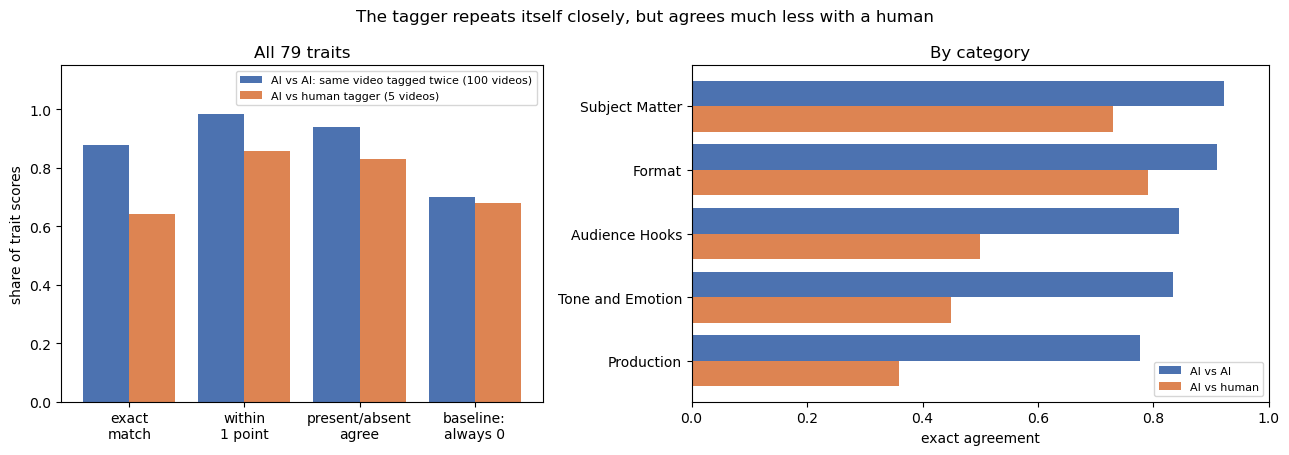

In [32]:
metric_labels = {"exact": "exact\nmatch", "within_1": "within\n1 point", "presence_agree": "present/absent\nagree",
                 "all_zeros_exact": "baseline:\nalways 0"}
df_human_category = pd.read_csv("../data/processed/agreement_by_category.csv").set_index("category")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})
positions = np.arange(len(metric_labels))
axes[0].bar(positions - 0.2, df_compare.loc["test-retest (AI vs AI)", list(metric_labels)], 0.4, color="#4C72B0",
            label=f"AI vs AI: same video tagged twice ({df_pairs['id'].nunique()} videos)")
axes[0].bar(positions + 0.2, df_compare.loc["AI vs human (5 videos)", list(metric_labels)], 0.4, color="#DD8452",
            label="AI vs human tagger (5 videos)")
axes[0].set_xticks(positions, list(metric_labels.values()))
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel("share of trait scores")
axes[0].legend(fontsize=8, loc="upper right")
axes[0].set_title("All 79 traits")
category_order = df_retag_category.sort_values("exact").index
positions = np.arange(len(category_order))
axes[1].barh(positions + 0.2, df_retag_category.loc[category_order, "exact"], 0.4, color="#4C72B0", label="AI vs AI")
axes[1].barh(positions - 0.2, df_human_category.loc[category_order, "exact"], 0.4, color="#DD8452", label="AI vs human")
axes[1].set_yticks(positions, category_order)
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("exact agreement")
axes[1].legend(fontsize=8, loc="lower right")
axes[1].set_title("By category")
fig.suptitle("The tagger repeats itself closely, but agrees much less with a human")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "retag_consistency.png"), dpi=150)
plt.show()

In [33]:
# ## Findings

In [34]:
# **Data:** 2,788 tagged videos, 51 channels, engagement at the 2026-11-04 snapshot. Lasso with nested alpha; 5-fold CV x 3 repeats (15 folds); R2 on log(1+views), mean ± sd over folds; gain = paired R2 gain over metadata-only.
#
# 1. **Random split (what notebooks 01-02 measured): traits look strong.** R2 0.34 -> 0.60 (gain +0.26 ± 0.02; MAE 1.47 -> 1.11 log units). But traits shuffled *within each channel* (channel identity kept, video link destroyed) give +0.25 ± 0.01, so about 95% of this gain is the traits acting as a channel fingerprint. Globally shuffled traits give 0.
# 2. **Held-out channels: traits carry real between-channel signal, very noisy.** Metadata alone ~0 (0.01 ± 0.30); with traits 0.17 ± 0.28 (gain +0.16 ± 0.18). Most of it is again channel-level trait mix (within-channel shuffle +0.13), i.e. "what kind of channel this is" predicts audience size for a new creator.
# 3. **Within channel (the product question): small but real.** R2 0.190 -> 0.204 (gain +0.014 ± 0.012; MAE 0.774 -> 0.763). Above all 50 shuffled runs (both shuffles: about -0.007). Likes: +0.033 ± 0.012. Age-normalized target (age curve, 30-day reference): +0.019 ± 0.010, same picture.
# 4. **Encodings:** ordinal >= coarse ≈ one-hot > presence. Presence-only loses the within-channel gain (-0.006), so intensity (0-4) matters; one-hot's extra columns do not help and overfit under Ridge (-0.015 within channel).
# 5. **Categories (alone, within channel):** Tone and Emotion (+0.014) and Audience Hooks (+0.011) carry the within-channel signal; Subject Matter does not (-0.008). Across channels, Production alone matches all traits (+0.18); Format and Subject Matter alone do not transfer. Dropping any one category changes little (redundancy).
# 6. **Traits most often selected within channel** (associations, not effects): suspense/cliffhanger (+), curiosity-gap hook (+), visual dependency (+), interview (+), livestream highlights (+); commentary (-), informational (-), promotional (-), podcast/long conversation (-), high energy (-), comedy (-).
# 7. **Test-retest:** 100 videos (44 channels, <= 10 min) re-tagged with the identical prompt/model/schema for ~$0.50: exact 88%, within-1 98%, mean abs diff 0.15, present/absent 94%, weighted kappa 0.94 (always-0 baseline 70%). AI vs human (5 videos): 64% / 86% / 0.55 / 83%. The tagger is highly repeatable; its disagreement with people is systematic (definitions/calibration), not random noise. Least repeatable: compilation (kappa 0.45), nostalgia (0.57), on-screen text (63% exact). Removing the 2 traits with kappa < 0.6 changes nothing.
#
# **Caveats:** one snapshot, ages 0-385 days (young videos clamp at the age curve's day 1); 51 channels so held-out folds swing widely; Shorts flag = duration <= 180 s; within-channel demeaning uses training-fold channel means; repeatability is not validity (the human comparison is only 5 videos).